In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
data=np.load('/kaggle/input/datasets/anubhashukla/new-charts-dataset/model_evaluations2.npz')
actuals,gnn,var=data['actuals'],data['gnn'],data['var']

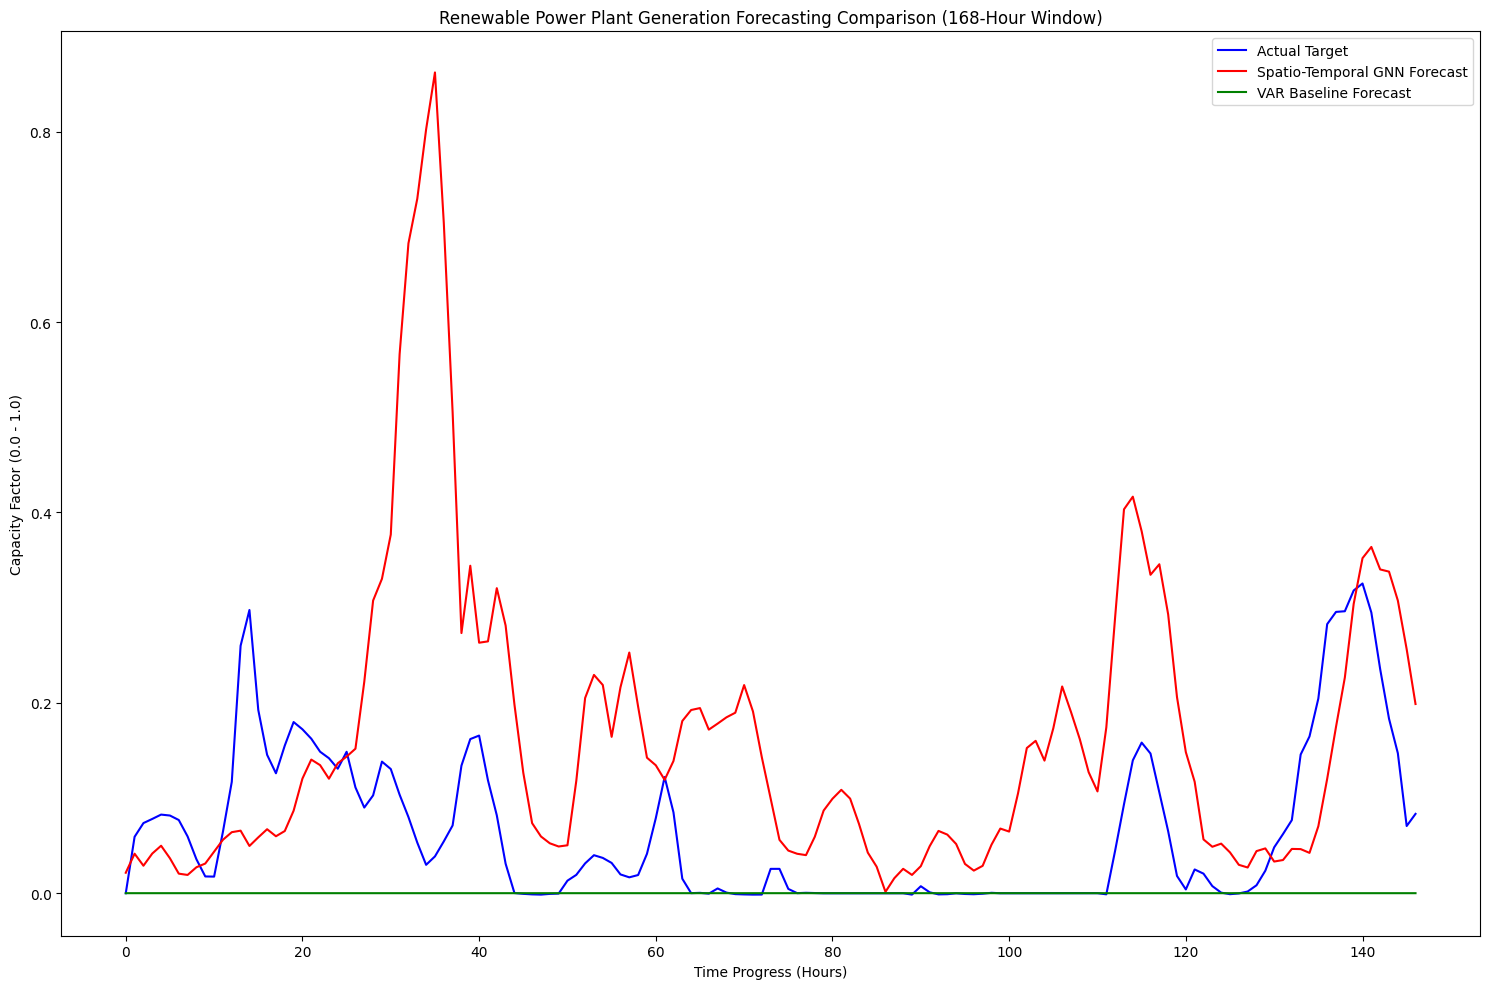

In [8]:
plt.figure(figsize=(15,10))
plt.plot(actuals[:168,0],label='Actual Target',color='blue')
plt.plot(gnn[:168,0],label='Spatio-Temporal GNN Forecast',color='red')
plt.plot(var[:168,0],label='VAR Baseline Forecast',color='green')

plt.title('Renewable Power Plant Generation Forecasting Comparison (168-Hour Window)')
plt.ylabel('Capacity Factor (0.0 - 1.0)')
plt.xlabel('Time Progress (Hours)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('forecasting_performance_line_chart.png', dpi=300)
plt.show()

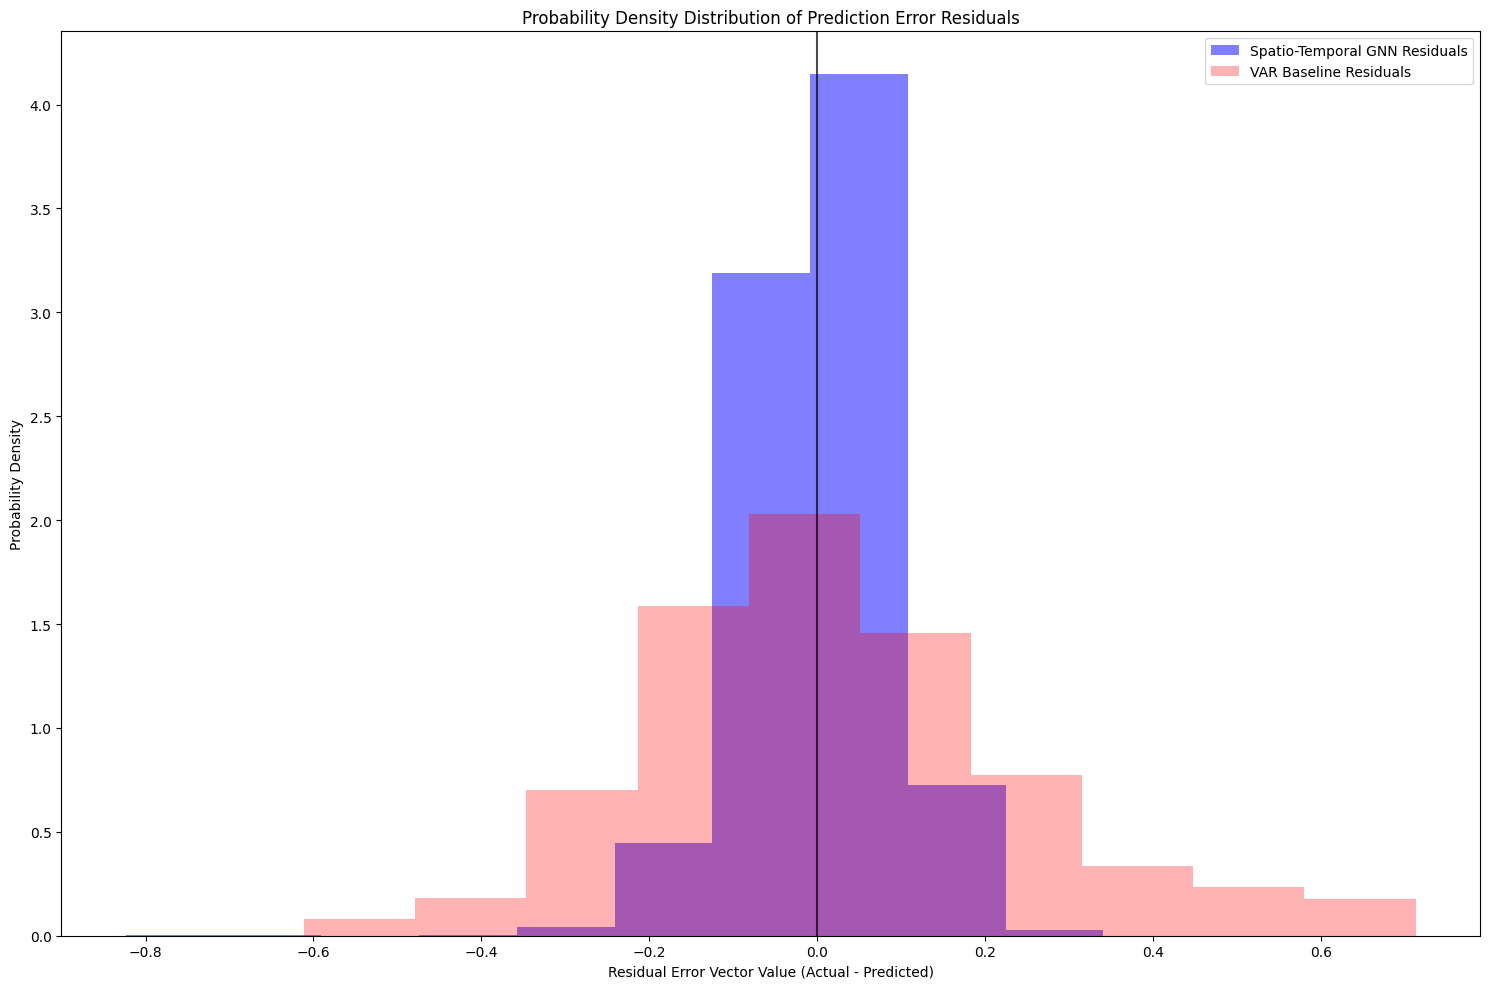

In [9]:
gnn_residuals=(actuals-gnn).flatten()
var_residuals=(actuals-var).flatten()

plt.figure(figsize=(15,10))
plt.hist(gnn_residuals,color='blue',alpha=0.5,density=True,label='Spatio-Temporal GNN Residuals')
plt.hist(var_residuals,color='red',alpha=0.3,density=True,label='VAR Baseline Residuals')

plt.axvline(0, color='black', linestyle='-', alpha=0.7)
plt.title('Probability Density Distribution of Prediction Error Residuals')
plt.xlabel('Residual Error Vector Value (Actual - Predicted)')
plt.ylabel('Probability Density')
plt.legend()
plt.tight_layout()
plt.savefig('2_residual_distribution_chart.png', dpi=300)
plt.show()

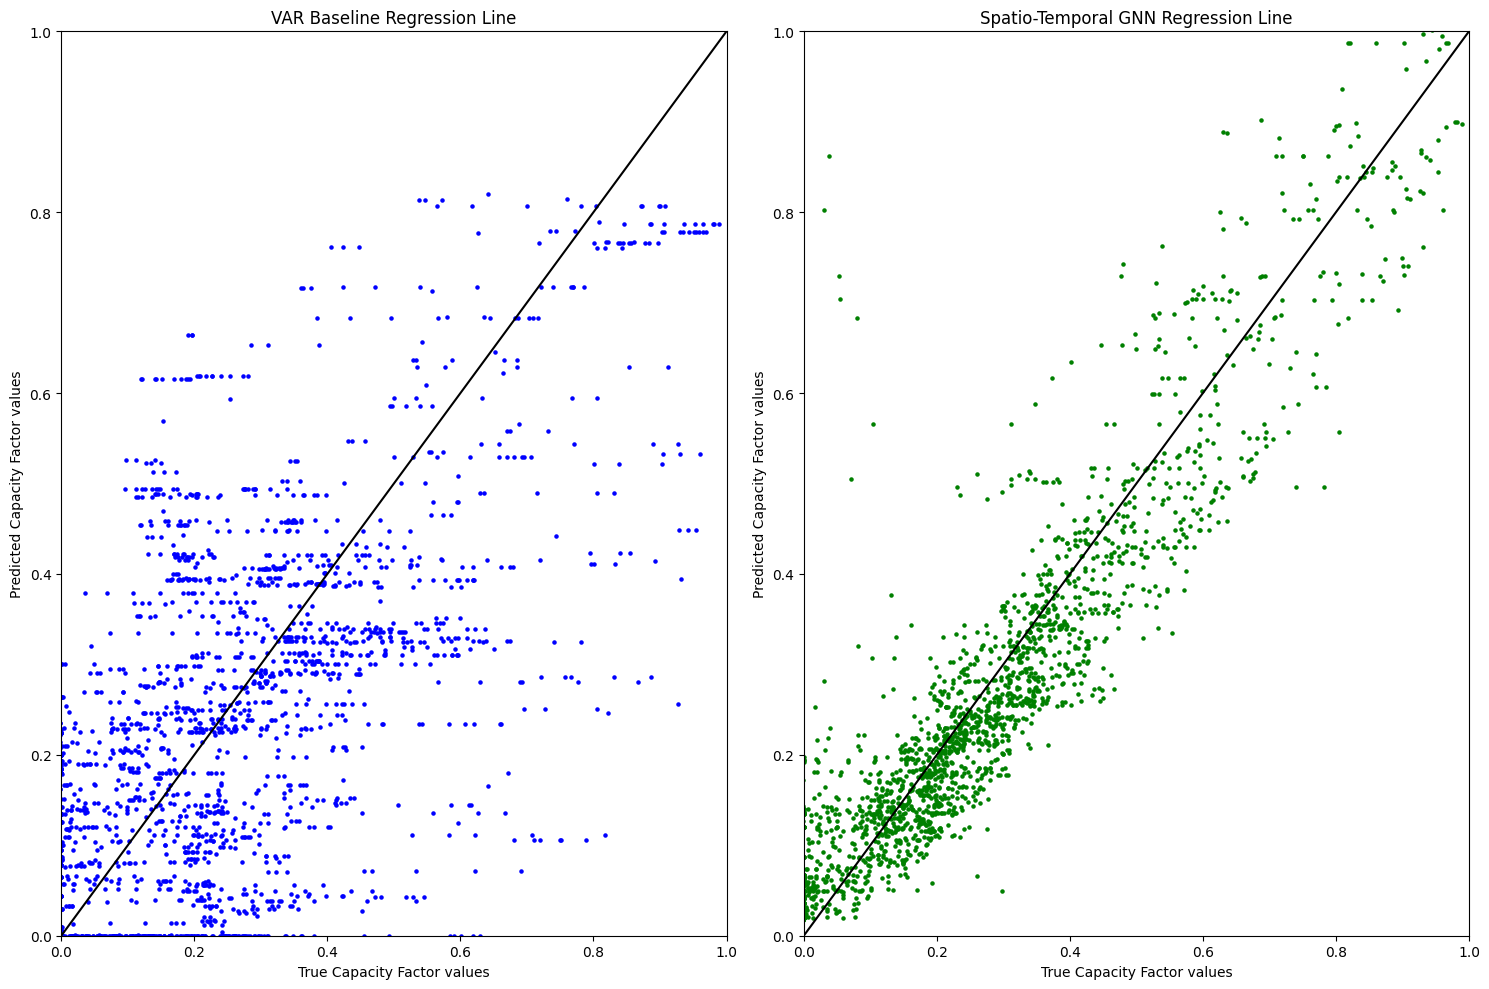

In [10]:
plt.figure(figsize=(15,10))

plt.subplot(1,2,1)
plt.scatter(actuals.flatten()[:2000],var.flatten()[:2000],color='blue',s=5)
plt.plot([0, 1], [0, 1], color='black', linestyle='-')
plt.title('VAR Baseline Regression Line')
plt.xlabel('True Capacity Factor values')
plt.ylabel('Predicted Capacity Factor values')
plt.xlim(0, 1)
plt.ylim(0, 1)


plt.subplot(1,2,2)
plt.scatter(actuals.flatten()[:2000],gnn.flatten()[:2000],color='green',s=5)
plt.plot([0, 1], [0, 1], color='black', linestyle='-')
plt.title('Spatio-Temporal GNN Regression Line')
plt.xlabel('True Capacity Factor values')
plt.ylabel('Predicted Capacity Factor values')
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig('3_regression_scatter_alignment.png', dpi=300)
plt.show()